# Question 1(c) — Implied Volatility Structure

## Objective

Estimate market-implied volatility from PLTR option midquotes using a self-implemented Black–Scholes implied volatility solver.

The analysis will examine:

- Implied volatility smiles across strikes.
- The implied volatility term structure across maturities.
- The implied volatility surface.
- ATM total variance and forward variance.
- Differences between historical volatility under the physical measure (P) and implied volatility under the risk-neutral measure (Q).

All option prices will be based on bid-ask midquotes. Invalid or inconsistent observations will be documented rather than silently removed.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq

def bs_call_price (S, K, r, T, sigma):
    d1 = (np.log(S/K)+(r+sigma**2/2)*(T))/(np.sqrt(T)*sigma)
    d2 = d1 - sigma*np.sqrt(T)

    call_price = norm.cdf(d1)*S - norm.cdf(d2)*K*np.exp(-r*T)

    return call_price

print(bs_call_price(100,100,0.005,1,0.20))

def implied_volatility(market_price, S,K,r,T):

    ## Set lower and upper boundary for pricing option value
    lower_bound = max(S-K*np.exp(-r*T), 0)
    upper_bound = S

    if market_price < lower_bound or market_price > upper_bound:
        return np.nan, "arbitrage_violation"

    def objective(sigma):
        return bs_call_price(S, K, r, T, sigma) - market_price

    sigma_low = 0.001
    sigma_high = 5.0

    f_low = objective(sigma_low)
    f_high = objective(sigma_high)
    if f_high*f_low >0:
        return np.nan, "no_bracket"

    
    try:
        iv = brentq(
            objective, 
            sigma_low, 
            sigma_high,
            xtol=1e-10,
            maxiter=100)
        return iv, "success"
    except ValueError:
        return np.nan, "solver_failure"

## Test
market_price = bs_call_price(100,100,0.05,1,0.20)
estimated_iv = implied_volatility(market_price, 100,100,0.05,1)
print("Market price: ", market_price)
print("Estimated volatility: ", estimated_iv)


8.197553910246697
Market price:  10.450583572185572
Estimated volatility:  (0.19999999999468607, 'success')


In [11]:
## Read file and combine data 

from pathlib import  Path
expiries_to_check = [
    "2026-11-20",
    "2026-12-18",
    "2027-01-15",
    "2027-02-19"
]

data_dir = Path("../Data")

call_dfs = []

for expiry in expiries_to_check:
    df = pd.read_csv(data_dir/ f"PLTR_calls_{expiry}.csv")
    call_dfs.append(df)

all_calls = pd.concat(call_dfs, ignore_index=True)

valid_calls = all_calls[
    (all_calls["bid"] > 0) &
    (all_calls["ask"] > 0) &
    (all_calls["ask"] >= all_calls["bid"])
]
valid_calls = valid_calls.copy()
valid_calls["mid"] = (valid_calls["ask"] + valid_calls["bid"])/2

print(valid_calls[["expiration", "strike", "bid", "ask", "mid"]].head())


   expiration  strike     bid     ask      mid
0  2026-11-20    25.0  183.05  185.35  184.200
1  2026-11-20    30.0  178.10  180.35  179.225
2  2026-11-20    35.0  173.10  174.90  174.000
3  2026-11-20    40.0  168.15  170.40  169.275
4  2026-11-20    45.0  162.75  165.40  164.075


In [12]:
valuation_date = pd.Timestamp("2026-10-9")
valid_calls["expiration"] = pd.to_datetime(
    valid_calls["expiration"]
)

valid_calls["T"] = (
    valid_calls["expiration"] - valuation_date
).dt.days/365

print(valid_calls[["expiration", "strike", "mid", "T"]].head())

#Set stock price and r, based on 2026/10/9
s0 = 209.05
r  = 0.045

valid_calls["iv_result"] = valid_calls.apply(
    lambda row: implied_volatility(
        row["mid"],
        s0,
        row["strike"],
        r,
        row["T"]
    ),
    axis = 1
)

valid_calls["calculated_iv"] = valid_calls["iv_result"].str[0]
valid_calls["iv_status"] = valid_calls["iv_result"].str[1]

  expiration  strike      mid         T
0 2026-11-20    25.0  184.200  0.115068
1 2026-11-20    30.0  179.225  0.115068
2 2026-11-20    35.0  174.000  0.115068
3 2026-11-20    40.0  169.275  0.115068
4 2026-11-20    45.0  164.075  0.115068


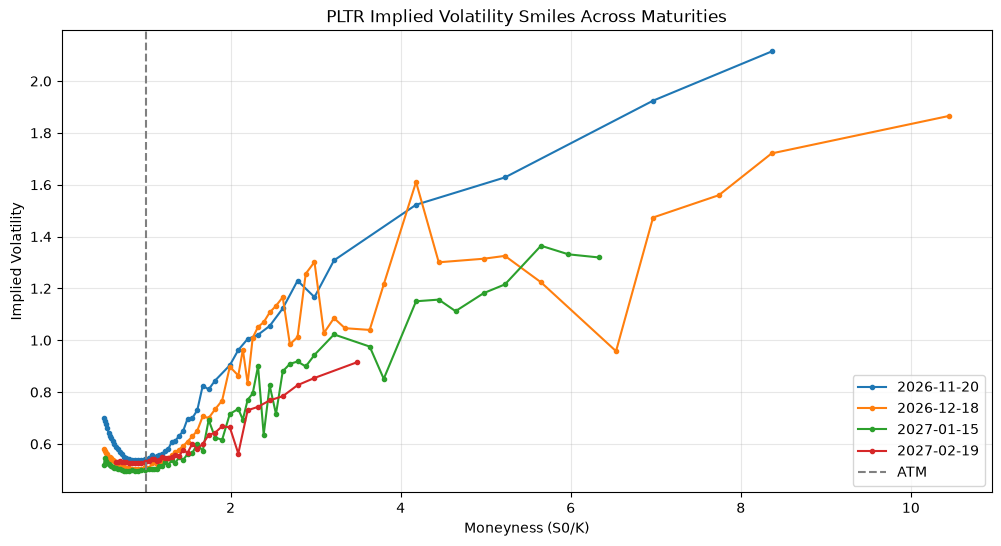

In [13]:
plt.figure(figsize=(12,6))
for expiry, group in valid_calls.groupby("expiration"):
    smile = group[group["iv_status"] == "success"].copy()

    smile["moneyness"] = s0 / smile["strike"]
    smile = smile.sort_values("moneyness")

    plt.plot(
        smile["moneyness"],
        smile["calculated_iv"],
        marker="o",
        markersize=3,
        label=str(expiry.date())
    )
plt.axvline(x=1, color="gray", linestyle="--", label="ATM")
plt.xlabel("Moneyness (S0/K)")
plt.ylabel("Implied Volatility")
plt.title("PLTR Implied Volatility Smiles Across Maturities")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


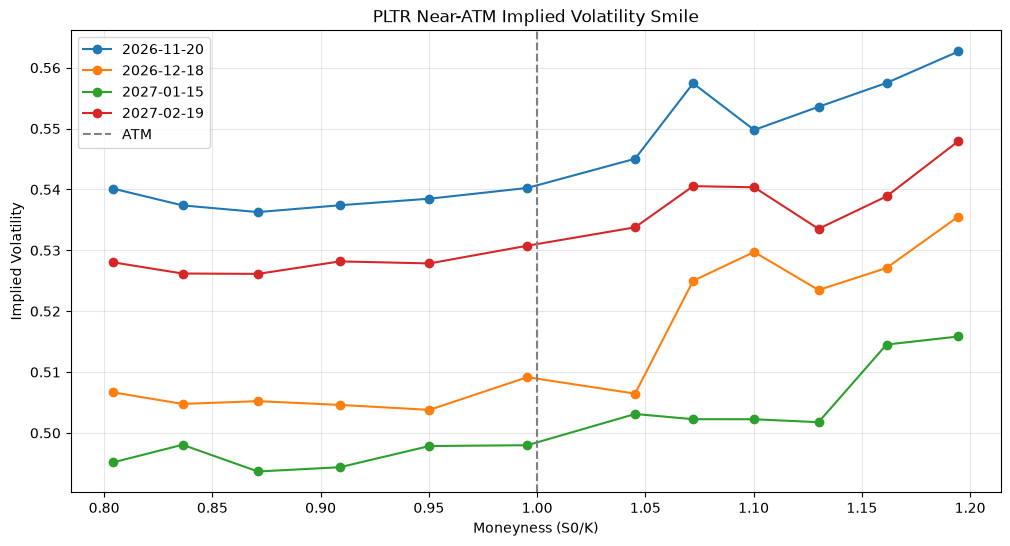

In [14]:
valid_calls["moneyness"] = (
    s0 / valid_calls["strike"]
)
near_atm_calls = valid_calls[
    (valid_calls["iv_status"] == "success") &
    (valid_calls["moneyness"] > 0.8) &
    (valid_calls["moneyness"] < 1.2)
].copy()

near_atm_calls["moneyness"] = (
    s0 / near_atm_calls["strike"]
)

plt.figure(figsize=(12, 6))

for expiry, group in near_atm_calls.groupby("expiration"):

    group = group.sort_values("moneyness")

    plt.plot(
        group["moneyness"],
        group["calculated_iv"],
        marker="o",
        label=str(expiry.date())
    )

plt.axvline(
    x=1,
    color="gray",
    linestyle="--",
    label="ATM"
)

plt.xlabel("Moneyness (S0/K)")
plt.ylabel("Implied Volatility")
plt.title("PLTR Near-ATM Implied Volatility Smile")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Near-ATM Implied Volatility Smile

To reduce the influence of deep-in-the-money contracts and potential quote distortions, the analysis focuses on options with moneyness between 0.8 and 1.2.

The resulting implied volatility curves are relatively flat around the at-the-money region, with a moderate upward skew toward higher values of S_0/K, corresponding to in-the-money call options.

The implied volatility levels also vary across maturities, indicating that market-implied volatility is not constant across either strike prices or expiration dates.

These findings highlight the limitations of the constant-volatility Black–Scholes model and motivate further analysis using time-varying and stochastic volatility models.

### ATM Implied Volatility Term Structure

For each maturity, the at-the-money (ATM) option is approximated
by selecting the call option with the strike closest to the
current stock price.

The ATM implied volatility term structure illustrates how
market-implied volatility varies across option maturities.

In [15]:
atm_options = valid_calls[
    valid_calls["iv_status"] == "success"
].copy()

atm_options["atm_distance"] = abs(
    atm_options["strike"] - s0
)

atm_idx = atm_options.groupby("expiration")["atm_distance"].idxmin()

atm_data = atm_options.loc[atm_idx].sort_values("T")

print(
    atm_data[
        ["expiration", "strike", "T", "calculated_iv"]
    ]
)

    expiration  strike         T  calculated_iv
36  2026-11-20   210.0  0.115068       0.540251
112 2026-12-18   210.0  0.191781       0.509163
185 2027-01-15   210.0  0.268493       0.497988
235 2027-02-19   210.0  0.364384       0.530760


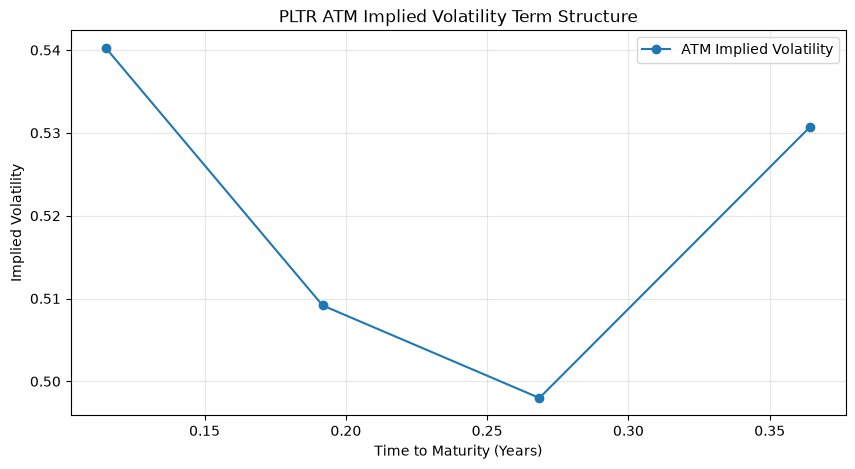

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(
    atm_data["T"],
    atm_data["calculated_iv"],
    marker="o",
    linestyle="-",
    label="ATM Implied Volatility"
)

plt.xlabel("Time to Maturity (Years)")
plt.ylabel("Implied Volatility")
plt.title("PLTR ATM Implied Volatility Term Structure")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The ATM implied volatility term structure describes the market-implied annualized volatility across different option maturities.

To examine how volatility expectations evolve over time, we first convert ATM implied volatility into **total implied variance**

We then estimate the **forward implied variance** between consecutive maturities using the change in total variance divided by the corresponding time interval


Taking the square root gives the annualized forward implied volatility for each interval. This allows us to examine the volatility implied for future periods rather than the entire horizon from today to expiration.

    expiration  total_variance  forward_variance  forward_volatility
36  2026-11-20        0.033585               NaN                 NaN
112 2026-12-18        0.049719          0.210311            0.458597
185 2027-01-15        0.066584          0.219853            0.468885
235 2027-02-19        0.102649          0.376107            0.613276


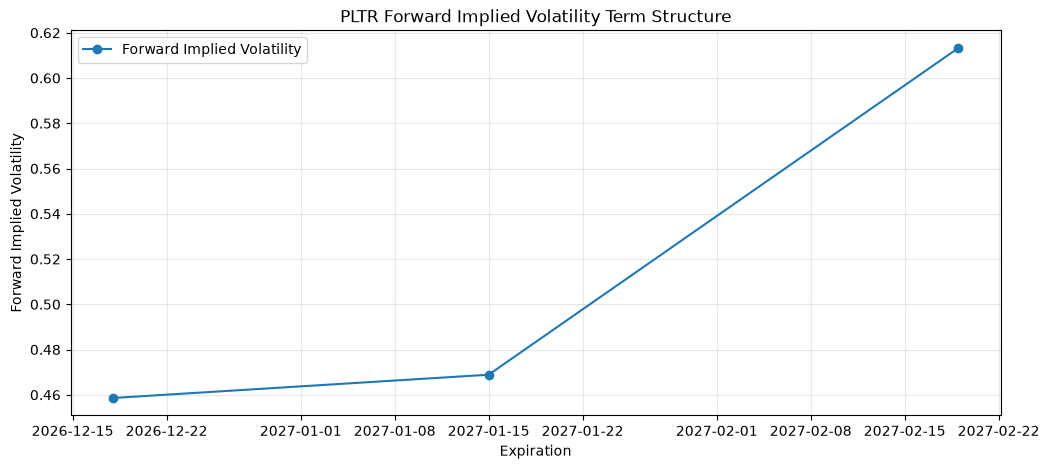

In [17]:
## Forward implied volatility term structure

atm_data["total_variance"] = atm_data["calculated_iv"]**2*atm_data["T"]

atm_data["forward_variance"] = (
    atm_data["total_variance"].diff()/atm_data["T"].diff()
)
atm_data["forward_volatility"] = np.sqrt(atm_data["forward_variance"])
print(
    atm_data[
        ["expiration", "total_variance",
         "forward_variance", "forward_volatility"]
    ]
)

atm_data["forward_variance"] = (
    atm_data["total_variance"].diff()
    / atm_data["T"].diff()
)

atm_data["forward_volatility"] = np.sqrt(
    atm_data["forward_variance"]
)

plt.figure(figsize=(12, 5))

plt.plot(
    atm_data["expiration"],
    atm_data["forward_volatility"],
    marker="o",
    linestyle="-",
    label="Forward Implied Volatility"
)

plt.xlabel("Expiration")
plt.ylabel("Forward Implied Volatility")
plt.title("PLTR Forward Implied Volatility Term Structure")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Interpretation: ATM Implied Volatility vs. Forward Implied Volatility

The ATM implied volatility term structure shows the annualized volatility implied over the entire period from the valuation date to each option expiration. In contrast, total implied variance measures the cumulative variance over that horizon, while forward implied volatility represents the annualized volatility implied for the interval between two consecutive maturities.

**Key Findings**

- **ATM Implied Volatility:** PLTR's ATM implied volatility initially decreases from approximately 54.0% to 49.8%, before increasing to 53.1% at the longest maturity.
- **Total Implied Variance:** Total variance increases across all four maturities, reflecting greater cumulative variance over longer horizons.
- **Forward Implied Volatility:** Forward volatility increases from approximately 45.9% to 61.3% across the three consecutive maturity intervals, suggesting higher volatility is implied for the later forward period.

Overall, the results demonstrate that ATM implied volatility and forward implied volatility provide different perspectives on the volatility term structure. The former summarizes volatility over the full remaining maturity, while the latter isolates the volatility implied for individual future intervals.

These estimates are derived from Black–Scholes implied volatilities and should be interpreted as model-implied quantities rather than direct forecasts of realized volatility.

### Physical vs Risk-Neutral Variance Forecasts

This section compares the risk-neutral implied total variance
extracted from option prices with the physical-measure variance
forecasts generated by three historical models:

1. Constant-volatility GBM
2. EWMA
3. GARCH(1,1)

All forecasts are evaluated at the same valuation date and
over matched option horizons.

In [18]:
## Import GBM historical benchmark for implied variance calculation
gbm_result = pd.read_csv("../Data/processed/gbm_result.csv")
gbm_vol = gbm_result["annualized_volatility"].iloc[0]
print(gbm_vol)

atm_data["gbm_total_variance"] = gbm_vol**2*atm_data["T"]

0.6728558718641469


In [19]:
## Import EWMA for implied variance calculation
ewma_result = pd.read_csv(
    "../Data/processed/ewma_result.csv"
)

ewma_daily_variance = ewma_result["daily_variance"].iloc[0]

print("EWMA daily variance:", ewma_daily_variance)
print("EWMA annualized volatility:",
      np.sqrt(ewma_daily_variance * 252))

atm_data["ewma_total_variance"] = (
    ewma_daily_variance * 252 * atm_data["T"]
)

print(
    atm_data[
        ["expiration", "T", "total_variance",
         "ewma_total_variance"]
    ]
)

EWMA daily variance: 0.0012683140039558
EWMA annualized volatility: 0.56534514148161
    expiration         T  total_variance  ewma_total_variance
36  2026-11-20  0.115068        0.033585             0.036778
112 2026-12-18  0.191781        0.049719             0.061296
185 2027-01-15  0.268493        0.066584             0.085814
235 2027-02-19  0.364384        0.102649             0.116462


In [20]:
garch_result = pd.read_csv(
    "../Data/processed/garch_result.csv"
)

print(garch_result.T)


omega = garch_result["omega"].iloc[0] / 10000
alpha = garch_result["alpha"].iloc[0]
beta = garch_result["beta"].iloc[0]

garch_next_variance = (
    garch_result["next_daily_variance"].iloc[0]
)

persistence = alpha + beta

long_run_variance = omega / (1 - persistence)

print("Persistence:", persistence)
print("Long-run daily variance:", long_run_variance)

def garch_total_variance(N):
    h = np.arange(1, N + 1)

    daily_forecast = (
        long_run_variance
        + persistence**(h - 1)
        * (garch_next_variance - long_run_variance)
    )

    return daily_forecast.sum()


                                0
forecast_date          2026-10-09
omega                    3.510181
alpha                    0.048707
beta                     0.756854
mu                        0.19626
next_daily_variance      0.001485
annualized_volatility    0.611688
Persistence: 0.8055608060376215
Long-run daily variance: 0.0018052847993776976


In [21]:
## Summarize data from three model
atm_data["N"] = np.round(
    atm_data["T"] * 252
).astype(int)

atm_data["garch_total_variance"] = (
    atm_data["N"].apply(garch_total_variance)
)

print(
    atm_data[
        [
            "expiration",
            "N",
            "total_variance",
            "ewma_total_variance",
            "garch_total_variance"
        ]
    ]
)

    expiration   N  total_variance  ewma_total_variance  garch_total_variance
36  2026-11-20  29        0.033585             0.036778              0.050708
112 2026-12-18  48        0.049719             0.061296              0.085005
185 2027-01-15  68        0.066584             0.085814              0.121111
235 2027-02-19  92        0.102649             0.116462              0.164438


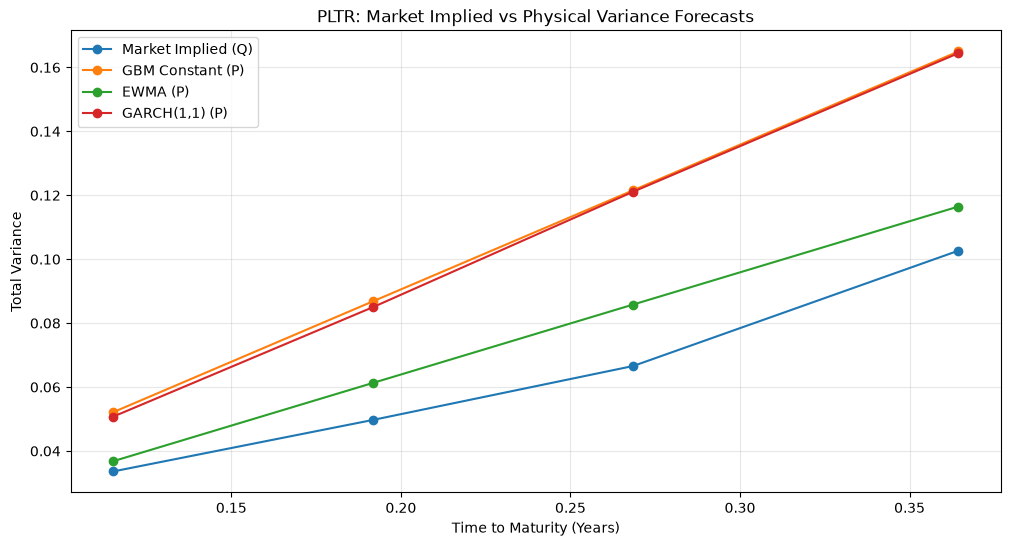

In [22]:
## Visualization of three model and total variance 

plt.figure(figsize=(12, 6))

models = {
    "Market Implied (Q)": "total_variance",
    "GBM Constant (P)": "gbm_total_variance",
    "EWMA (P)": "ewma_total_variance",
    "GARCH(1,1) (P)": "garch_total_variance"
}

for label, column in models.items():
    plt.plot(
        atm_data["T"],
        atm_data[column],
        marker="o",
        label=label
    )

plt.xlabel("Time to Maturity (Years)")
plt.ylabel("Total Variance")
plt.title("PLTR: Market Implied vs Physical Variance Forecasts")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [23]:
## Three model result summary table 
models = [
    "gbm_total_variance",
    "ewma_total_variance",
    "garch_total_variance"
]

for model in models:
    atm_data[model + "_gap"] = (
        atm_data[model] - atm_data["total_variance"]
    )

print(
    atm_data[
        ["expiration"] +
        [model + "_gap" for model in models]
    ]
)

    expiration  gbm_total_variance_gap  ewma_total_variance_gap  \
36  2026-11-20                0.018510                 0.003192   
112 2026-12-18                0.037107                 0.011577   
185 2027-01-15                0.054972                 0.019230   
235 2027-02-19                0.062320                 0.013813   

     garch_total_variance_gap  
36                   0.017123  
112                  0.035287  
185                  0.054527  
235                  0.061789  


### Comparison of Market-Implied and Physical Variance Forecasts

The analysis compares PLTR's Black–Scholes ATM implied total variance with forecasts generated by three historical volatility models: constant-volatility GBM, EWMA, and GARCH(1,1), across four option maturities.

All three physical-measure variance forecasts exceed the corresponding market-implied total variance estimates. Among the historical models, EWMA produces the lowest variance forecasts and is consistently closest to market-implied values.

The GBM and GARCH(1,1) forecasts are particularly similar. This reflects the proximity between the GBM historical volatility estimate and the long-run volatility implied by the fitted GARCH model. Unlike GBM, however, GARCH incorporates time-varying conditional variance and mean reversion.

**Physical versus Risk-Neutral Measures**

The GBM, EWMA, and GARCH forecasts are estimated from historical returns under the physical probability measure (P). In contrast, option-implied volatility is inferred from observed option prices using the Black–Scholes framework and reflects risk-neutral market pricing (Q).

Differences between these quantities may reflect volatility risk premia, model assumptions, and market conditions. They should not be interpreted directly as forecasting errors or arbitrage opportunities.

**Limitations**

The analysis uses a limited number of option maturities and relies on Black–Scholes pricing assumptions. In addition, the precise option quotation timestamps are not fully verified against the historical model information cutoff. These limitations should be considered when interpreting the results.

### (d) Evidence Judgment

**Conclusion: Reject the statement.**

Even if GARCH(1,1) achieves the lowest out-of-sample forecasting error, this does not imply that its latest conditional volatility is necessarily the correct input for option pricing.

First, GARCH estimates conditional volatility under the **physical probability measure (P)** using historical returns, whereas option prices are determined under the **risk-neutral measure (Q)**. The difference may reflect volatility risk premia, market expectations, and model assumptions.

Second, out-of-sample forecasting performance does not necessarily imply superior option-pricing performance. The model validation evaluates variance forecasts against squared realized returns using mean squared error (MSE), rather than directly testing option-pricing accuracy.

Third, the empirical results reveal meaningful differences between GARCH forecasts and market-implied variance. For example, for the November 20, 2026 maturity, the GARCH total variance forecast is approximately 0.0507, compared with a market-implied total variance of 0.0336. Similar differences are observed across the other maturities.

Therefore, GARCH provides a useful estimate of future volatility under the physical measure, but its conditional volatility should not automatically be treated as the appropriate risk-neutral volatility for option pricing. Additional calibration to market option prices or an appropriate risk-neutral pricing framework would be required.

In [ ]:
print(valid_calls["iv_status"].value_counts())

print(
    valid_calls.groupby(
        ["expiration", "iv_status"]
    ).size()
)


violations = valid_calls[
    valid_calls["iv_status"] == "arbitrage_violation"
].copy()

violations["lower_bound"] = np.maximum(
    s0 - violations["strike"] * np.exp(-r * violations["T"]),
    0
)

violations["upper_bound"] = s0

violations["violation_type"] = np.where(
    violations["mid"] < violations["lower_bound"],
    "below_lower_bound",
    "above_upper_bound"
)

print(violations["violation_type"].value_counts())

iv_status
success                226
arbitrage_violation     20
Name: count, dtype: int64
expiration  iv_status          
2026-11-20  arbitrage_violation     5
            success                52
2026-12-18  arbitrage_violation     7
            success                69
2027-01-15  arbitrage_violation     8
            success                65
2027-02-19  success                40
dtype: int64
violation_type
below_lower_bound    20
Name: count, dtype: int64


In [26]:
print(atm_data[
    [
        "expiration",
        "T",
        "N",
        "calculated_iv",
        "total_variance",
        "gbm_total_variance",
        "ewma_total_variance",
        "garch_total_variance"
    ]
].to_string(index=False))

print("\nMissing values:")
print(atm_data[
    [
        "total_variance",
        "gbm_total_variance",
        "ewma_total_variance",
        "garch_total_variance"
    ]
].isna().sum())

expiration        T  N  calculated_iv  total_variance  gbm_total_variance  ewma_total_variance  garch_total_variance
2026-11-20 0.115068 29       0.540251        0.033585            0.052096             0.036778              0.050708
2026-12-18 0.191781 48       0.509163        0.049719            0.086826             0.061296              0.085005
2027-01-15 0.268493 68       0.497988        0.066584            0.121556             0.085814              0.121111
2027-02-19 0.364384 92       0.530760        0.102649            0.164969             0.116462              0.164438

Missing values:
total_variance          0
gbm_total_variance      0
ewma_total_variance     0
garch_total_variance    0
dtype: int64


In [27]:
print("Valuation date:", valuation_date)
print("Spot price:", s0)
print("Risk-free rate:", r)

print("\nOption trade dates:")
print(
    all_calls["lastTradeDate"].agg(["min", "max"])
)

Valuation date: 2026-10-09 00:00:00
Spot price: 209.05
Risk-free rate: 0.045

Option trade dates:
min    2026-08-06 17:00:52+00:00
max    2026-10-09 19:59:58+00:00
Name: lastTradeDate, dtype: str


In [28]:
# Check last trade timestamps of selected ATM options

atm_trade_audit = valid_calls.loc[
    atm_data.index,
    ["expiration", "strike", "lastTradeDate", "bid", "ask"]
].copy()

atm_trade_audit["lastTradeDate"] = pd.to_datetime(
    atm_trade_audit["lastTradeDate"],
    utc=True
)

print(atm_trade_audit.to_string(index=False))

expiration  strike             lastTradeDate   bid   ask
2026-11-20   210.0 2026-10-09 19:59:54+00:00 15.20 15.45
2026-12-18   210.0 2026-10-09 19:58:58+00:00 18.85 19.05
2027-01-15   210.0 2026-10-09 19:58:47+00:00 22.00 22.35
2027-02-19   210.0 2026-10-09 19:59:48+00:00 27.30 28.10
